In [1]:
#importing library
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import data_utils as du

In [2]:
#importing dataset
reg_path= "../../data/Regression_datasets/civil.csv"
reg_data= pd.read_csv(reg_path)
print(reg_data.head())

       cement       water  aggregates    strength
0  335.255462  153.612508  550.715080  201.648201
1  243.976349  192.200723  345.942816  106.896167
2  151.623525  135.493297  670.793244  115.278790
3  396.217433  131.282038  247.477877  199.617536
4  395.119620  175.572228  425.190884  201.403467


In [3]:
#data exploration
du.data_exploration(reg_data)

DATA EXPLORATION
Shape of dataset: 10000 rows, 4 columns

Columns: ['cement', 'water', 'aggregates', 'strength']

Data Types:
 cement        float64
water         float64
aggregates    float64
strength      float64
dtype: object

Missing Values:
 cement        0
water         0
aggregates    0
strength      0
dtype: int64

Statistical Summary:
              cement         water    aggregates      strength
count  10000.000000  10000.000000  10000.000000  10000.000000
mean     299.059983    124.839677    498.945052    174.587341
std      115.467249     43.287184    171.863298     61.303010
min      100.000208     50.002721    200.178095     20.646078
25%      199.079676     87.340459    352.243950    125.844508
50%      297.815185    124.360182    497.313302    173.929215
75%      399.719619    162.571513    646.867715    224.352731
max      499.992743    199.996391    799.863467    334.652378


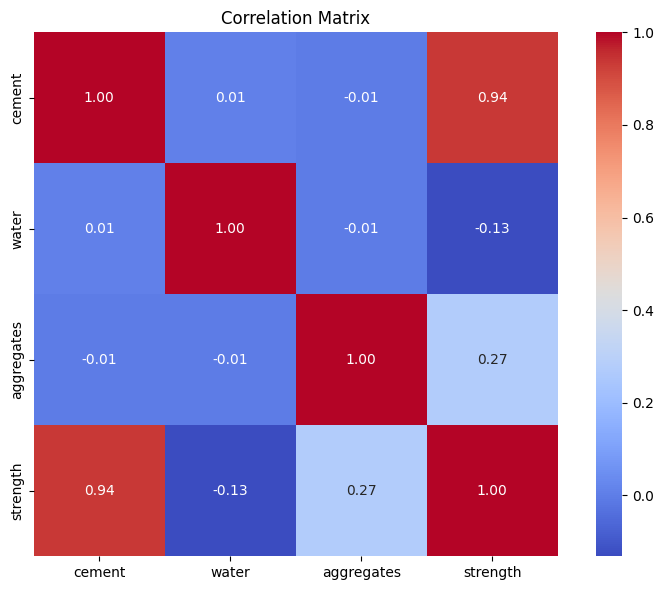

In [4]:
#correlation analysis
corr = du.get_correlation_matrix(reg_data)
du.plot_correlation_matrix(corr)


strength and cement have almost 94% correlation ship.


In [5]:
#linear regression 
X=reg_data.drop(columns=['strength'], axis=1)
y=reg_data['strength']

model, mse, r2, y_test, y_pred  = du.linear_regression_model(X, y)

Mean Squared Error: 100.6082
R-squared: 0.9732


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [6]:
du.cross_validation(model, X, y, cv=5)

5-Fold Cross-Validation (r2): [0.97414053 0.97206578 0.97410566 0.9729076  0.97159155]
Average CV score: 0.9730 (± 0.0010)


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i

array([0.97414053, 0.97206578, 0.97410566, 0.9729076 , 0.97159155])

Almost 97% able to predict.

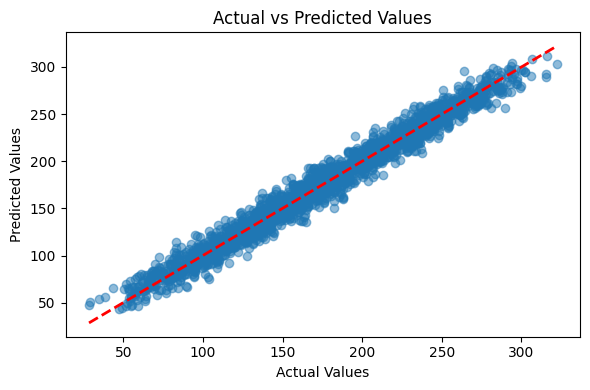

In [7]:
du.plot_actual_vs_predicted(y_test, y_pred)

/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


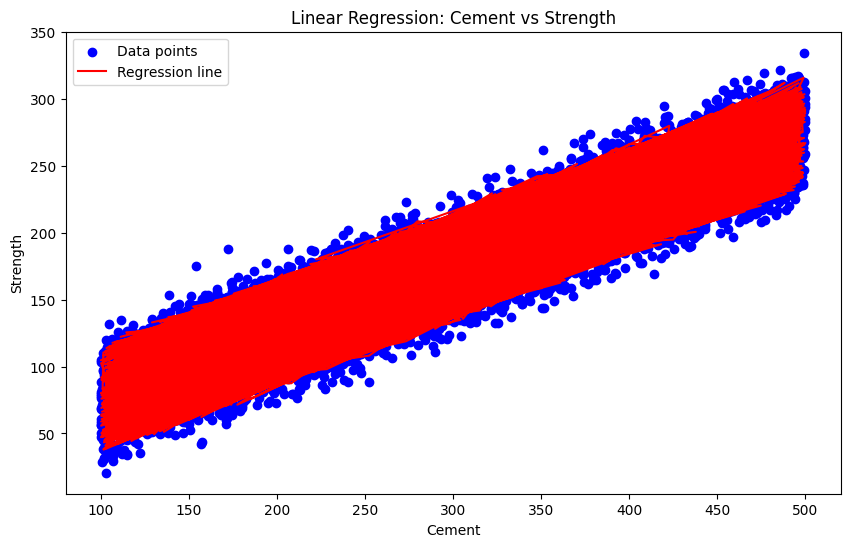

In [8]:
plt.figure(figsize=(10, 6))
plt.scatter(reg_data['cement'], reg_data['strength'], color='blue', label='Data points')
# Plotting the regression line
plt.plot(reg_data['cement'], model.predict(X), color='red', label='Regression line')
plt.xlabel('Cement')
plt.ylabel('Strength')
plt.title('Linear Regression: Cement vs Strength')
plt.legend()    

In [9]:
columns = reg_data.columns.tolist()

df_clean = du.remove_outliers_iqr(reg_data, columns, factor=1.5)

In [10]:
df_clean.shape

(10000, 4)

In [11]:
X_clean = df_clean.drop(columns=['strength'], axis=1)
y_clean = df_clean['strength']
du.linear_regression_model(X_clean, y_clean)

Mean Squared Error: 100.6082
R-squared: 0.9732


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


(LinearRegression(),
 100.60817884093328,
 0.9732266235632099,
 6252    160.288937
 4684    277.867938
 1731    143.909255
 4742    189.525358
 4521    220.826140
            ...    
 6412    187.023105
 8285    225.805518
 7853    167.284916
 1095    100.441571
 6929    177.311462
 Name: strength, Length: 2000, dtype: float64,
 array([167.56885419, 259.67070939, 155.75708815, ..., 192.83068661,
        113.61460427, 182.50125296], shape=(2000,)))

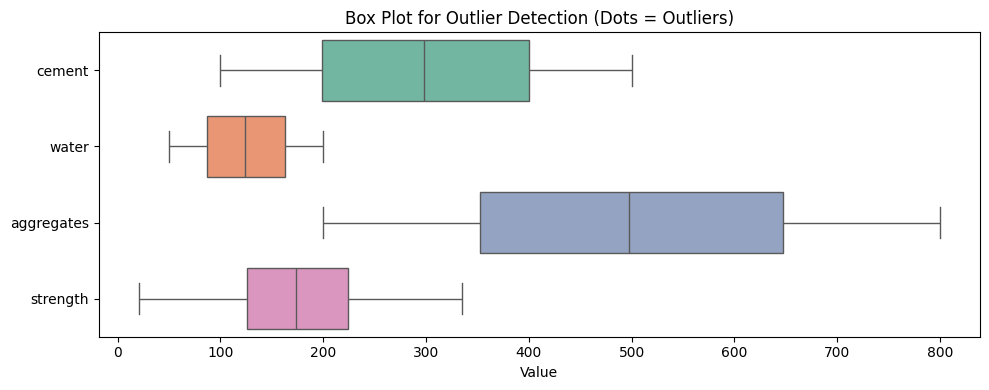

In [12]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_clean[columns], orient='h', palette='Set2')
plt.title("Box Plot for Outlier Detection (Dots = Outliers)")
plt.xlabel("Value")
plt.tight_layout()
plt.show()

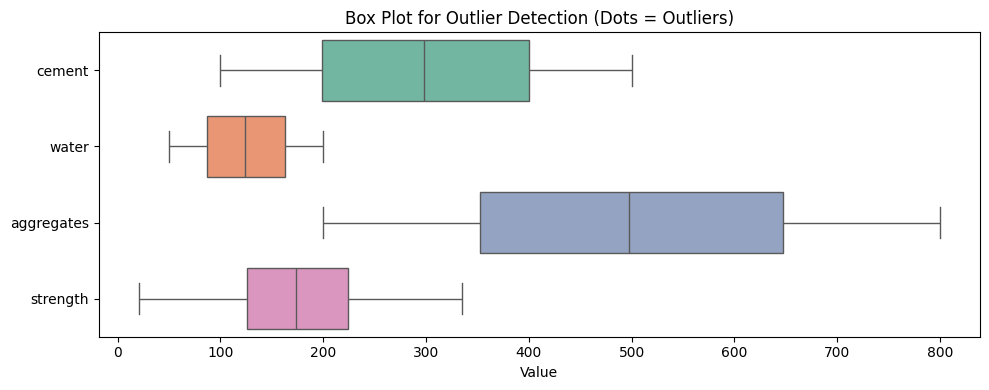

In [14]:
du.plot_boxplots(df_clean, columns)

There is no outlayer present for data